In [1]:
import numpy as np
import matplotlib.pyplot as plt
from accuracy_bounds.regressionproblems.feasible_sets import feasible_sets_features_nn_xy
from accuracy_bounds.regressionproblems.kersize_compute import compute_kernel_size

# Create 2d meshgrid and surface data with noise

In this example we create a regression dataset consisting of a meshgrid of noisy input data and noisy function values at each point in the meshgrid. We will split the data into a train and test dataset, compute the average kernel size on both splits, as well as the full dataset and fit two different regression models to the dataset and see that the root mean squared errors (RMSE) of the models on the test dataset are above half of the average kernel size computed on the test dataset.

In [2]:
def noisy_meshgrid_2d_regression(bounds: float, n_sqrt_mesh: int, input_noise: float):
    """
    Generate a 2D meshgrid for regression tasks.
    """
    
    # Create grid
    x = np.linspace(-bounds, bounds, n_sqrt_mesh)
    y = np.linspace(-bounds, bounds, n_sqrt_mesh)
    X, Y = np.meshgrid(x, y)

    # Noise levels
    input_noise = input_noise

    # Add noise to inputs
    X_noisy = X + input_noise * np.random.randn(*X.shape)
    Y_noisy = Y + input_noise * np.random.randn(*Y.shape)

    return X_noisy, Y_noisy

def sin_sqrt_surface_from_meshgrid(X: np.array, Y: np.array, output_noise: float):
    """
    Compute a surface from the given meshgrid.
    """

    R = np.divide(np.sqrt(X**2 + Y**2),0.9)
    F_clean = 0.5*np.sin(1+R)  

    # Add noise to output
    F_noisy = F_clean + output_noise * np.random.randn(*F_clean.shape)

    return F_noisy

## Visualize noisy surface

We create noisy input and target data and visulaize the input and target data.

First we visualize the target data:

Text(0.5, 0.92, 'sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

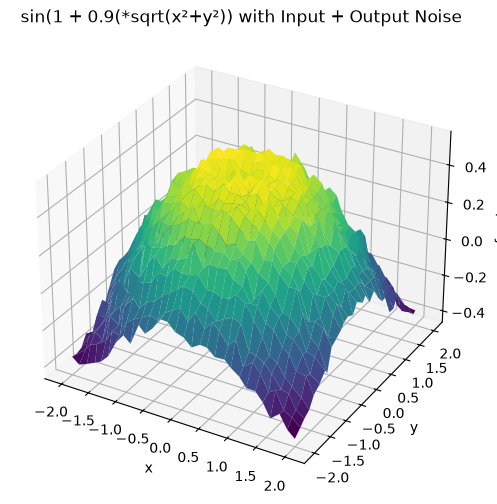

In [3]:
# Reproducibility
np.random.seed(42)

# Create grid
bounds = 2
n_sqrt_mesh = 30

# Noise levels
input_noise = 0.01 # this relates to tau_x = sqrt(0.01^2+0.01^2) = 0.014
output_noise = 0.03 # this is tau_y = 0.03

# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
F_noisy = sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise) 

# Plot
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_noisy, Y_noisy, F_noisy, cmap='viridis', edgecolor='none')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f noisy')
ax.set_title('sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

#plt.tight_layout()
#plt.show()

Now we visualize the meshgrid of input data:

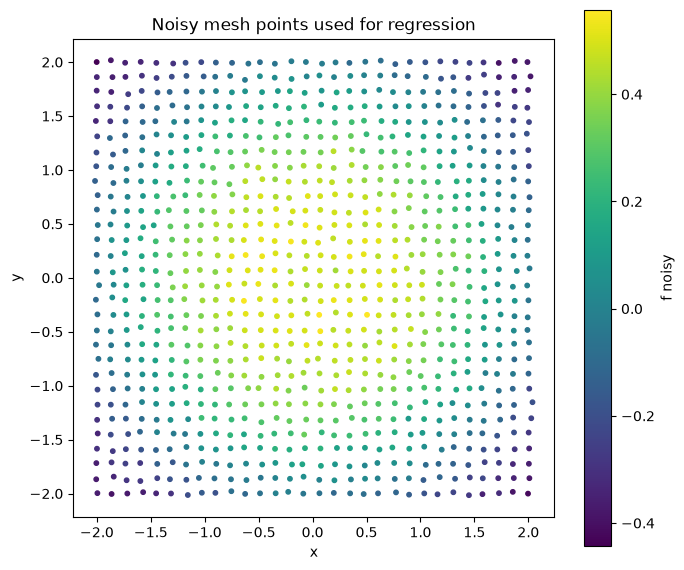

In [4]:
# Plot mesh points used for regression
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    X_noisy.ravel(),
    Y_noisy.ravel(),
    s=10,
    c=F_noisy.ravel(),
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Noisy mesh points used for regression")

cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label("f noisy")

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Create noisy data

We create noisy input and noisy output data as numpy arrays.

In [5]:
# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
tuples_input = np.vstack([X_noisy.ravel(), Y_noisy.ravel()]).T # sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise))

tuples_target = [sin_sqrt_surface_from_meshgrid(x, y, output_noise) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]
tuples_target = np.asarray(tuples_target).reshape(-1, 1)

final_tuples = [(np.array([x, y]), sin_sqrt_surface_from_meshgrid(x, y, output_noise)) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]

## Construct feasible sets

Now we compute the feasible sets for the whole dataset. We have $K = 30 \times 30 = 900$ samples, and for each sample we create a feasible set of maximum size

$$
N_{\max} = 300.
$$

For an anchor input point $x_i$, where $i \in \{0,\ldots,899\}$, all targets $y_j$ that satisfy

$$
\lVert y_i - y_j \rVert_2 \leq \tau_y
$$

and all targets $y_{j'}$ associated with an input that satisfies

$$
\lVert x_i - x_{j'} \rVert_2 \leq \tau_x
$$

are included in the feasible set with respect to the anchor input $x_i$.

We choose

$$
\tau_x = \sqrt{0.01^2 + 0.01^2} \approx 0.014
$$

and

$$
\tau_y = 0.03
$$

based on the worst-case noise threshold. The first function returns a dictionary, where `result_feas["feasible_sets"]` contains a list of such feasible sets. With the feasible sets we construct an extended dataset, `result_feas["D_prime"]`, that contains all the samples in the original dataset, as well as all samples with the anchor input sample and the target samples in the feasible set.

In [6]:
result_feas= feasible_sets_features_nn_xy(tuples_input,tuples_target, N_max=300, tau_x=0.014, tau_y=0.03, ext_D = True)

Now we compute the average kernel size from the feasible sets. Half of the average kernel size computed on the full dataset can be used as a lower bound for the RMSE of any regressor $\phi$ on the extended full dataset, result_feas["D_prime"], and on the full dataset. For the best, i.e. optimal regressors $\phi$ the average kernel size is an upper bound
$$
\frac{1}{2}Kersize(\mathcal D_{M'},2)_K
\leq
RMSE(\mathcal D_{M'},\phi)
\leq
Kersize(\mathcal D_{M'},2)_K.
$$

In [7]:
kersize, M_prime, Nk_stats = compute_kernel_size(result_feas["feasible_sets"])
print("average kernelsize", kersize)


average kernelsize 0.023903483897870715


## Regressors trained to approximate function 


Now we train three different regressors on a training dataset and test them on a held-out test dataset.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF,
    ConstantKernel,
    WhiteKernel,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
)

Here we split the data into training and testing data.

In [9]:
X = tuples_input                          # (N,2)
y = tuples_target.ravel()                 # (N,)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.7,
    random_state=42,
)

### Average kernel size on train data

We compute the feasible sets and from those the average kernel size on the training dataset. 

In [10]:
y_trainf = np.asarray(y_train).reshape(-1, 1)
result_feas_train= feasible_sets_features_nn_xy(X_train,y_trainf, N_max=300, tau_x=0.014, tau_y=0.03, ext_D = True)

In [11]:
kersize, M_prime, Nk_stats = compute_kernel_size(result_feas_train["feasible_sets"])
print("average kernelsize train", kersize)


average kernelsize train 0.023049904739291034


### Average kernel size on train data against Nmax

We compute an ablation over the maximum number of nearest neighbors of the average kernel size on the training dataset. We choose the number at which the average kernel size has converged up to the order of $10^{-4}$.

In [12]:
kersize_list =[]
tau_x_list = []
y_trainf = np.asarray(y_train).reshape(-1, 1)

for N_max in [10,20,30,40,50,100,200,300,450]:

    result_feas_train= feasible_sets_features_nn_xy(X_train,y_trainf, N_max=N_max, tau_x=0.014, tau_y=0.03, ext_D = True)
    kersize, M_prime, Nk_stats = compute_kernel_size(result_feas_train["feasible_sets"])

    kersize_list.append(kersize)
    tau_x_list.append(result_feas_train["tau_x"])

print("average kernelsize train", kersize_list)
print("tau_x", tau_x_list)


average kernelsize train [0.013601862946284668, 0.02043548940790086, 0.022399313134981984, 0.023049904739291034, 0.023049904739291034, 0.023049904739291034, 0.023049904739291034, 0.023049904739291034, 0.023049904739291034]
tau_x [0.014, 0.014, 0.014, 0.014, 0.014, 0.014, 0.014, 0.014, 0.014]


### Average kernel size on test data 

We compute the feasible sets and from those the average kernel size on the testing dataset. 

In [13]:
y_testf = np.asarray(y_test).reshape(-1, 1)
result_feas_test= feasible_sets_features_nn_xy(X_test,y_testf, N_max=300, tau_x=0.014, tau_y=0.03, ext_D = True)

In [14]:
kersize, M_prime, Nk_stats = compute_kernel_size(result_feas["feasible_sets"])
print("average kernelsize test", kersize)


average kernelsize test 0.023903483897870715


### Average kernel size on test data against Nmax

We compute an ablation over the maximum number of nearest neighbors of the average kernel size on the testing dataset. We choose the number at which the average kernel size has converged up to the order of $10^{-4}$.

In [15]:
kersize_list =[]
tau_x_list = []
y_testf = np.asarray(y_test).reshape(-1, 1)

for N_max in [10,20,30,40,50,100,200,300,450]:

    result_feas_test= feasible_sets_features_nn_xy(X_test,y_testf, N_max=N_max, tau_x=0.014, tau_y=0.03, ext_D = True)
    kersize, M_prime, Nk_stats = compute_kernel_size(result_feas_test["feasible_sets"])

    kersize_list.append(kersize)
    tau_x_list.append(result_feas_test["tau_x"])

print("average kernelsize test", kersize_list)
print("tau_x", tau_x_list)

average kernelsize test [0.0073771203699409165, 0.012848871027919075, 0.01711435907331654, 0.020848371267876375, 0.02274878711264051, 0.0236884913979613, 0.0236884913979613, 0.0236884913979613, 0.0236884913979613]
tau_x [0.014, 0.014, 0.014, 0.014, 0.014, 0.014, 0.014, 0.014, 0.014]


### MLP Regressor

We now train an MLP on the training dataset and compute the RMSE on the test dataset.

In [16]:
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(128, 128,128),
        activation="relu",
        solver="adam",
        learning_rate_init=1e-3,
        max_iter=5000,
        random_state=42,
    ))
])

mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)

print("MLP")
print("RMSE test =", np.sqrt(mean_squared_error(y_test, y_pred_mlp)))
print("R²   =", r2_score(y_test, y_pred_mlp))

MLP
RMSE test = 0.03691508306324466
R²   = 0.9790002794189087


### Gaussian process regressor

We now train an GP on the training dataset and compute the RMSE on the test dataset

In [17]:

kernel = (
    ConstantKernel(1.0)
    * RBF(length_scale=0.9)
    + WhiteKernel(noise_level=0.0009)
)

gpr = Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            optimizer=None,
            random_state=42,
        ))
    ])

gpr.fit(X_train, y_train)

y_pred_gpr = gpr.predict(X_test)

print("\nGaussian Process")
print("RMSE test =", np.sqrt(mean_squared_error(y_test, y_pred_gpr)))
print("R²   =", r2_score(y_test, y_pred_gpr))


Gaussian Process
RMSE test = 0.03341095881072044
R²   = 0.9827978118241026


In [18]:
grid = np.column_stack([X_noisy.ravel(), Y_noisy.ravel()])

F_mlp = mlp.predict(grid).reshape(X_noisy.shape)
F_gpr = gpr.predict(grid).reshape(X_noisy.shape)

### Plot MLP prediction

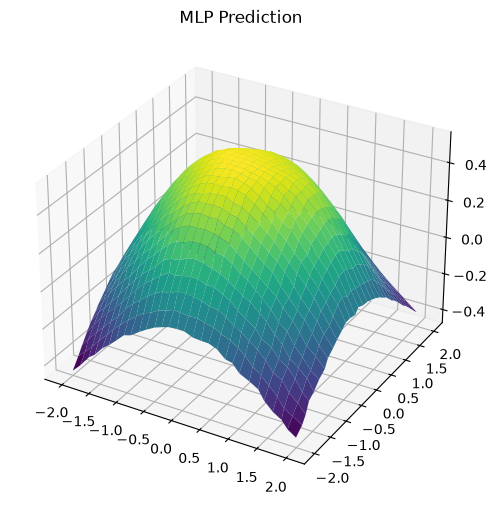

In [19]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X_noisy,
    Y_noisy,
    F_mlp,
    cmap="viridis",
    edgecolor="none",
)

ax.set_title("MLP Prediction")
plt.show()

### Plot GP prediction

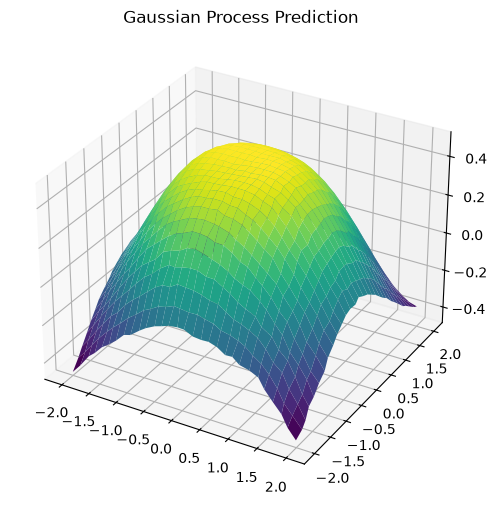

In [20]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X_noisy,
    Y_noisy,
    F_gpr,
    cmap="viridis",
    edgecolor="none",
)

ax.set_title("Gaussian Process Prediction")
plt.show()

## Evaluate MLP and GP on extended dataset constructed with feasible sets

We now evaluate the MLP and GP on the extended dataset constructed with the samples from the feasible sets and the corresponding input anchor points.

In [21]:
D_prime = result_feas["D_prime"]

X_prime = np.vstack([x for x, y in D_prime])
y_prime = np.asarray([y for x, y in D_prime]).ravel()

print(X_prime.shape)
print(y_prime.shape)

(57730, 2)
(57730,)


Here we can check if the RMSE on the enlarged dataset of the regressors is near the RMSE on the test dataset.

In [22]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# MLP
yhat_mlp = mlp.predict(X_prime)

print("MLP on D'")
print("RMSE :", np.sqrt(mean_squared_error(y_prime, yhat_mlp)))
print("MAE  :", mean_absolute_error(y_prime, yhat_mlp))
print("R²   :", r2_score(y_prime, yhat_mlp))

# GP
yhat_gp = gpr.predict(X_prime)

print("\nGP on D'")
print("RMSE :", np.sqrt(mean_squared_error(y_prime, yhat_gp)))
print("MAE  :", mean_absolute_error(y_prime, yhat_gp))
print("R²   :", r2_score(y_prime, yhat_gp))

MLP on D'
RMSE : 0.039896731889810966
MAE  : 0.031747001638949945
R²   : 0.9700218271212934

GP on D'
RMSE : 0.03453457054687729
MAE  : 0.027480159472888743
R²   : 0.9775385062452493


# Average Kernel Size for increasing noise thresholds

To investigate how the accuracy bounds change with different noise levels on the inputs and targets, we compute the average kernel size for a range of different noise levels. Recall that, half of the average kernel size computed on the full dataset can be used as a lower bound for the RMSE of any regressor $\phi$ on the extended full dataset, result_feas["D_prime"], and on the full dataset. For the best, i.e. optimal regressors $\phi$ the average kernel size is an upper bound
$$
\frac{1}{2}Kersize(\mathcal D_{M'},2)_K
\leq
RMSE(\mathcal D_{M'},\phi)
\leq
Kersize(\mathcal D_{M'},2)_K.
$$ 
Thus, we expect that it is harder to fit a regressor to data with higher noise levels and, hence, expect the average kernel size to increase with increasing noise levels - both on the input and target data. 

## Average Kernel Size against increasing input noise

In [23]:
# Reproducibility
np.random.seed(42)

# Create grid
bounds = 1
n_sqrt_mesh = 50

# Noise levels
input_noise = 0.01
output_noise = 0.01

kersize_list = []
M_prime_list = []
Nk_stats_list = []
tau_x_list = []

for input_noise in [0.01, 0.05, 0.1, 0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:

    # Add noise to inputs
    X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

    # Compute function with noisy inputs
    tuples_input = np.vstack([X_noisy.ravel(), Y_noisy.ravel()]).T # sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise))

    tuples_target = [sin_sqrt_surface_from_meshgrid(x, y, output_noise) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]
    tuples_target = np.asarray(tuples_target).reshape(-1, 1)

    final_tuples = [(np.array([x, y]), sin_sqrt_surface_from_meshgrid(x, y, output_noise)) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]

    tau_x = np.sqrt(input_noise**2 + input_noise**2)  # tau_x = sqrt(input_noise^2 + input_noise^2) 

    result_feas= feasible_sets_features_nn_xy(tuples_input,tuples_target, N_max=300, tau_x=tau_x, tau_y=output_noise, ext_D = False)
    kersize, M_prime, Nk_stats = compute_kernel_size(result_feas["feasible_sets"])

    kersize_list.append(kersize)
    M_prime_list.append(M_prime)
    Nk_stats_list.append(Nk_stats)
    tau_x_list.append(result_feas["tau_x"])

print("kernelsizes", kersize_list)
print("M_prime", M_prime_list)
print("Nk_stats", Nk_stats_list)
print("tau_x", tau_x_list)


kernelsizes [0.00596150555509014, 0.007100657932242954, 0.011193363585586312, 0.024578087614804775, 0.041733907716612256, 0.06339126183138864, 0.0867726464080578, 0.10327318204376909, 0.1350157182814605, 0.15497492949886837, 0.1804439306397063, 0.20708033459741457]
M_prime [634419, 653367, 698920, 855087, 1087583, 1109505, 1093003, 1093302, 1035168, 1020295, 978565, 941257]
Nk_stats [(2, 253.7676, 302.0, 303), (2, 261.3468, 309.0, 319), (4, 279.568, 334.0, 357), (2, 342.0348, 419.0, 473), (6, 435.0332, 528.0, 602), (3, 443.802, 511.5, 602), (2, 437.2012, 451.0, 602), (3, 437.3208, 437.0, 602), (9, 414.0672, 402.0, 602), (11, 408.118, 384.5, 602), (24, 391.426, 370.0, 602), (28, 376.5028, 357.0, 583)]
tau_x [np.float64(0.01414213562373095), np.float64(0.07071067811865477), np.float64(0.14142135623730953), np.float64(0.28284271247461906), np.float64(0.4242640687119285), np.float64(0.5656854249492381), np.float64(0.7071067811865476), np.float64(0.848528137423857), np.float64(0.98994949366

## Average Kernel Size against increasing target noise

In [ ]:
# Reproducibility
np.random.seed(42)

# Create grid
bounds = 1
n_sqrt_mesh = 50

# Noise levels
input_noise = 0.01
output_noise = 0.01

kersize_list = []
M_prime_list = []
Nk_stats_list = []
tau_x_list = []

for output_noise in [0.01, 0.05, 0.1, 0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:

    # Add noise to inputs
    X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

    # Compute function with noisy inputs
    tuples_input = np.vstack([X_noisy.ravel(), Y_noisy.ravel()]).T # sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise))

    tuples_target = [sin_sqrt_surface_from_meshgrid(x, y, output_noise) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]
    tuples_target = np.asarray(tuples_target).reshape(-1, 1)

    final_tuples = [(np.array([x, y]), sin_sqrt_surface_from_meshgrid(x, y, output_noise)) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]

    tau_x = np.sqrt(input_noise**2 + input_noise**2)  # tau_x = sqrt(input_noise^2 + input_noise^2) 

    result_feas= feasible_sets_features_nn_xy(tuples_input,tuples_target, N_max=300, tau_x=tau_x, tau_y=output_noise, ext_D = False)
    kersize, M_prime, Nk_stats = compute_kernel_size(result_feas["feasible_sets"])

    kersize_list.append(kersize)
    M_prime_list.append(M_prime)
    Nk_stats_list.append(Nk_stats)
    tau_x_list.append(result_feas["tau_x"])

print("kernelsizes", kersize_list)
print("M_prime", M_prime_list)
print("Nk_stats", Nk_stats_list)
print("tau_x", tau_x_list)


kernelsizes [0.00596150555509014, 0.015563158271448212, 0.025522697961770476, 0.04741170914396601, 0.0715548881014713, 0.09788677288777008, 0.11382205093666979, 0.1434880980802051, 0.16264406677789447, 0.19172761780598496, 0.21384674260339984, 0.23709872536643367]
M_prime [634419, 733157, 742218, 746781, 744703, 745060, 748120, 746860, 745713, 745132, 745673, 745053]
Nk_stats [(2, 253.7676, 302.0, 303), (2, 293.2628, 302.0, 303), (20, 296.8872, 302.0, 304), (25, 298.7124, 302.0, 304), (37, 297.8812, 302.0, 304), (19, 298.024, 302.0, 303), (6, 299.248, 302.0, 304), (3, 298.744, 302.0, 303), (7, 298.2852, 302.0, 303), (9, 298.0528, 302.0, 304), (4, 298.2692, 302.0, 304), (8, 298.0212, 302.0, 304)]
tau_x [np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562373095), np.float64(0.01414213562

## Average Kernel Size against increasing input and target noise

In [25]:
import numpy as np

# Reproducibility
np.random.seed(42)

# Grid parameters
bounds = 1
n_sqrt_mesh = 50

# Noise levels
noise_levels = np.array(
    [0.01, 0.05, 0.1, 0.2, 0.3, 0.4,
     0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
)

# Fixed quantiles
qx = 0.01
qy = 0.01

# Storage
kernel_size_surface = np.zeros(
    (len(noise_levels), len(noise_levels))
)

M_prime_surface = np.zeros_like(kernel_size_surface)

Nk_surface = np.zeros_like(kernel_size_surface, dtype=float)


# Loop over input and output noise
for i, input_noise in enumerate(noise_levels):

    for j, output_noise in enumerate(noise_levels):

        print(
            f"Running sigma_x={input_noise}, sigma_y={output_noise}"
        )

        # Generate noisy input mesh
        X_noisy, Y_noisy = noisy_meshgrid_2d_regression(
            bounds,
            n_sqrt_mesh,
            input_noise
        )

        # Input tuples
        tuples_input = np.vstack(
            [X_noisy.ravel(), Y_noisy.ravel()]
        ).T


        # Generate noisy outputs
        tuples_target = [
            sin_sqrt_surface_from_meshgrid(
                x,
                y,
                output_noise
            )
            for x, y in zip(
                X_noisy.ravel(),
                Y_noisy.ravel()
            )
        ]

        tuples_target = np.asarray(
            tuples_target
        ).reshape(-1,1)


        # Compute feasible sets
        result_feas = feasible_sets_features_nn_xy(
            tuples_input,
            tuples_target,
            N_max=300,
            qx=qx,
            qy=qy,
            ext_D=False
        )


        # Kernel size
        kersize, M_prime, Nk_stats = compute_kernel_size(
            result_feas["feasible_sets"]
        )


        # Store values
        kernel_size_surface[i,j] = kersize
        M_prime_surface[i,j] = M_prime

        # Store average neighborhood size from Nk_stats
        # Nk_stats = (min, mean, median, max)
        Nk_surface[i,j] = Nk_stats[1]


print("Kernel size surface:")
print(kernel_size_surface)

print("M prime surface:")
print(M_prime_surface)

Running sigma_x=0.01, sigma_y=0.01
Running sigma_x=0.01, sigma_y=0.05
Running sigma_x=0.01, sigma_y=0.1
Running sigma_x=0.01, sigma_y=0.2
Running sigma_x=0.01, sigma_y=0.3
Running sigma_x=0.01, sigma_y=0.4
Running sigma_x=0.01, sigma_y=0.5
Running sigma_x=0.01, sigma_y=0.6
Running sigma_x=0.01, sigma_y=0.7
Running sigma_x=0.01, sigma_y=0.8
Running sigma_x=0.01, sigma_y=0.9
Running sigma_x=0.01, sigma_y=1.0
Running sigma_x=0.05, sigma_y=0.01
Running sigma_x=0.05, sigma_y=0.05
Running sigma_x=0.05, sigma_y=0.1
Running sigma_x=0.05, sigma_y=0.2
Running sigma_x=0.05, sigma_y=0.3
Running sigma_x=0.05, sigma_y=0.4
Running sigma_x=0.05, sigma_y=0.5
Running sigma_x=0.05, sigma_y=0.6
Running sigma_x=0.05, sigma_y=0.7
Running sigma_x=0.05, sigma_y=0.8
Running sigma_x=0.05, sigma_y=0.9
Running sigma_x=0.05, sigma_y=1.0
Running sigma_x=0.1, sigma_y=0.01
Running sigma_x=0.1, sigma_y=0.05
Running sigma_x=0.1, sigma_y=0.1
Running sigma_x=0.1, sigma_y=0.2
Running sigma_x=0.1, sigma_y=0.3
Running sigma

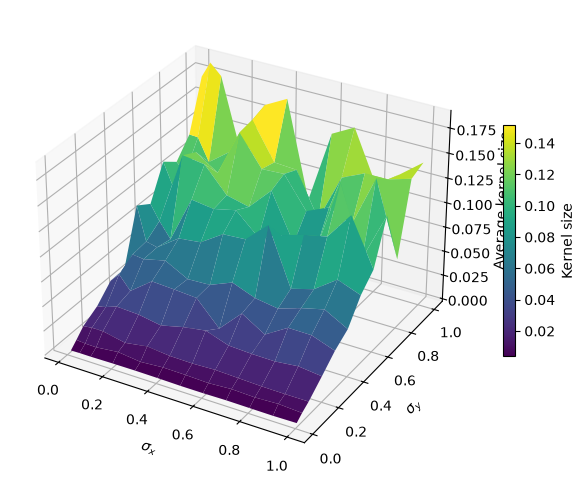

In [26]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


SX, SY = np.meshgrid(
    noise_levels,
    noise_levels
)


fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")


surf = ax.plot_surface(
    SX,
    SY,
    kernel_size_surface.T,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel(r"$\sigma_x$")
ax.set_ylabel(r"$\sigma_y$")
ax.set_zlabel("Average kernel size")

fig.colorbar(
    surf,
    shrink=0.5,
    label="Kernel size"
)

plt.show()

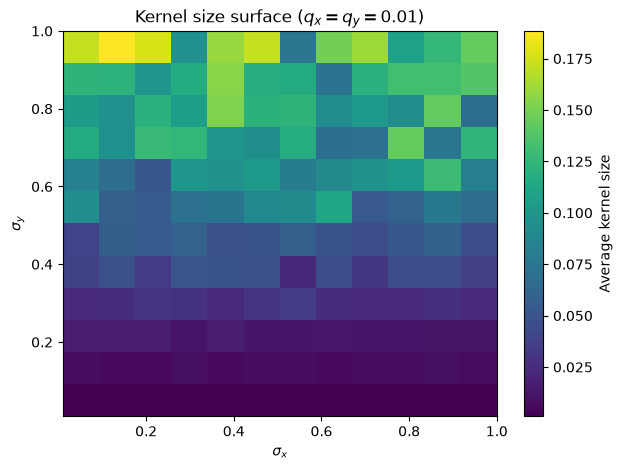

In [27]:
plt.figure(figsize=(7,5))

plt.imshow(
    kernel_size_surface.T,
    origin="lower",
    extent=[
        noise_levels.min(),
        noise_levels.max(),
        noise_levels.min(),
        noise_levels.max()
    ],
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Average kernel size")

plt.xlabel(r"$\sigma_x$")
plt.ylabel(r"$\sigma_y$")
plt.title(
    r"Kernel size surface ($q_x=q_y=0.01$)"
)

plt.show()